In [ ]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
from sklearn.model_selection import train_test_split
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error



In [ ]:
# Load Dataset
df = pd.read_csv('/content/quikr_car (1).csv')



In [ ]:
# DATA CLEANING
# Remove invalid years and convert to integer
df = df[df['year'].astype(str).str.isnumeric()]
df['year'] = df['year'].astype(int)

In [ ]:
# Remove rows with "Ask For Price"
df = df[df['Price'] != 'Ask For Price']


In [ ]:
# Convert Price to integer
df['Price'] = df['Price'].str.replace(',', '')
df['Price'] = df['Price'].astype(int)

# Clean kms_driven column
df['kms_driven'] = df['kms_driven'].str.replace(',', '')
df['kms_driven'] = df['kms_driven'].str.split(' ').str[0]
df = df[df['kms_driven'].str.isnumeric()]
df['kms_driven'] = df['kms_driven'].astype(int)

# Remove rows with missing fuel type
df = df[~df['fuel_type'].isna()]

# Keep first 3 words of car name
df['name'] = df['name'].str.split(' ').str[:3].str.join(' ')

# Reset index
df.reset_index(drop=True, inplace=True)

In [ ]:
# Display cleaned data
print(df.head())
print("\nDataset Shape:", df.shape)


                     name   company  year   Price  kms_driven fuel_type
0     Hyundai Santro Xing   Hyundai  2007   80000       45000    Petrol
1     Mahindra Jeep CL550  Mahindra  2006  425000          40    Diesel
2       Hyundai Grand i10   Hyundai  2014  325000       28000    Petrol
3  Ford EcoSport Titanium      Ford  2014  575000       36000    Diesel
4               Ford Figo      Ford  2012  175000       41000    Diesel

Dataset Shape: (816, 6)


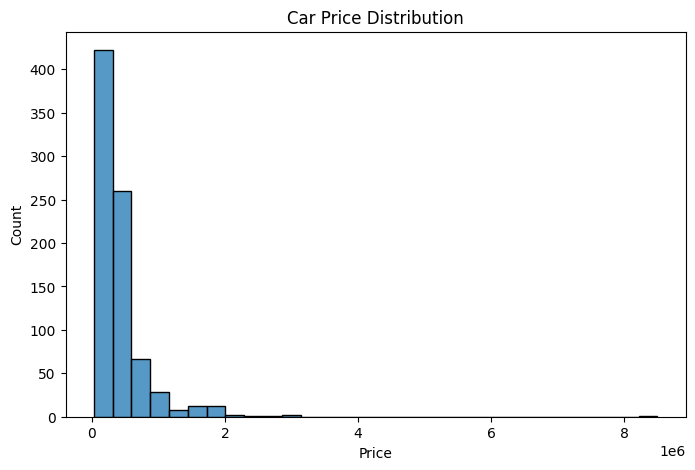

In [ ]:
# EXPLORATORY DATA ANALYSIS (EDA)
# Price Distribution
plt.figure(figsize=(8,5))
sns.histplot(df['Price'], bins=30)
plt.title("Car Price Distribution")
plt.xlabel("Price")
plt.ylabel("Count")
plt.show()

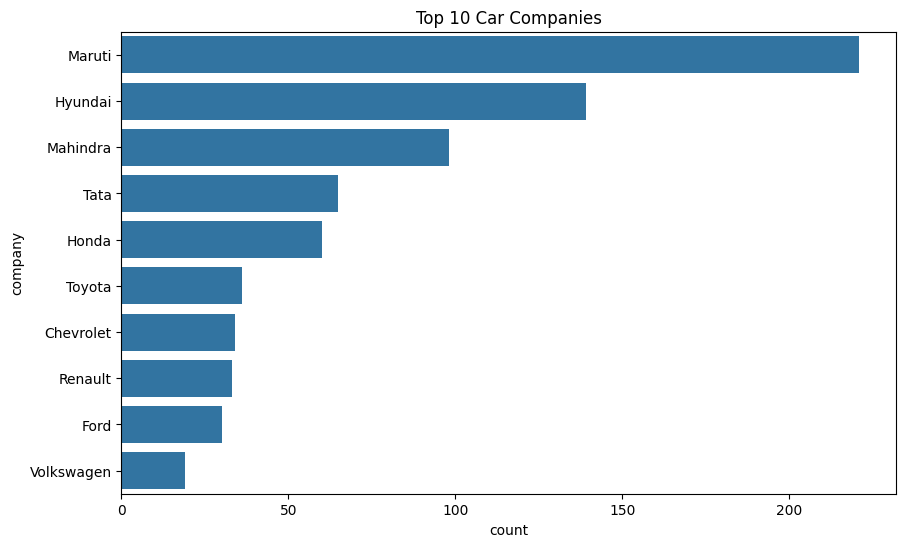

In [ ]:
# Top Companies
plt.figure(figsize=(10,6))
sns.countplot(
    y='company',
    data=df,
    order=df['company'].value_counts().head(10).index
)
plt.title("Top 10 Car Companies")
plt.show()

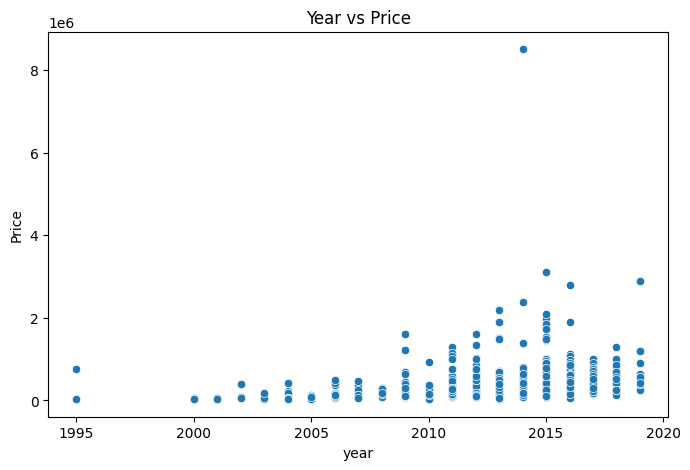

In [ ]:
# Year vs Price
plt.figure(figsize=(8,5))
sns.scatterplot(x='year', y='Price', data=df)
plt.title("Year vs Price")
plt.show()

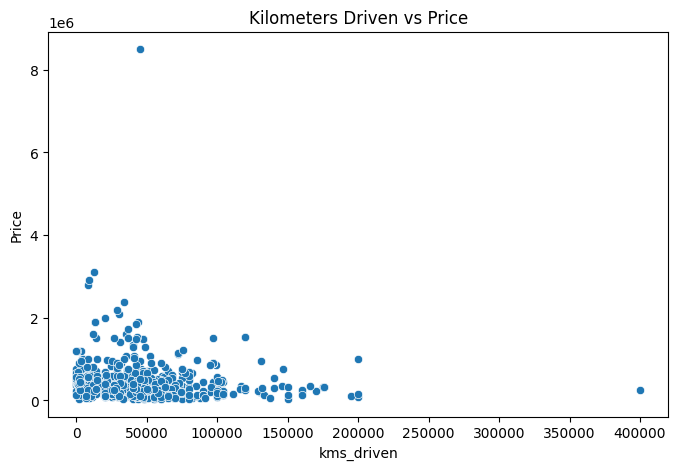

In [ ]:
# Kms Driven vs Price
plt.figure(figsize=(8,5))
sns.scatterplot(x='kms_driven', y='Price', data=df)
plt.title("Kilometers Driven vs Price")
plt.show()

In [ ]:
# FEATURE SELECTION
X = df.drop(columns='Price')
y = df['Price']

In [ ]:
# TRAIN TEST SPLIT
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
# PREPROCESSING & MODEL
ohe = OneHotEncoder(handle_unknown='ignore')

column_trans = make_column_transformer(
    (ohe, ['name', 'company', 'fuel_type']),
    remainder='passthrough'
)

model = LinearRegression()

pipe = make_pipeline(
    column_trans,
    model
)

In [ ]:
# MODEL TRAINING
pipe.fit(X_train, y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('columntransformer',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('onehotencoder',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['name', 'company',
                                                   'fuel_type'])])),
                ('linearregression', LinearRegression())])

In [ ]:
# MODEL EVALUATION
y_pred = pipe.predict(X_test)
print("\nModel Performance")
print("R2 Score :", r2_score(y_test, y_pred))
print("MAE      :", mean_absolute_error(y_test, y_pred))


Model Performance
R2 Score : 0.1935478302108793
MAE      : 185571.80528898624


In [ ]:
# SAVE MODEL
pickle.dump(pipe, open('CarPricePredictor.pkl', 'wb'))
print("\nModel Saved Successfully!")



Model Saved Successfully!


In [ ]:
# SAMPLE PREDICTION
sample = pd.DataFrame({
    'name': ['Maruti Suzuki Swift'],
    'company': ['Maruti'],
    'year': [2018],
    'kms_driven': [40000],
    'fuel_type': ['Petrol']
})

predicted_price = pipe.predict(sample)

print("\nPredicted Car Price: ₹", int(predicted_price[0]))


Predicted Car Price: ₹ 385083
